# Spaceship Titanic — 2. Modelling and Evaluation

Consumes the feature matrices exported by `01_data_preparation.ipynb`.

**Protocol.** Every model is evaluated with the *same* repeated stratified
cross-validation: 5 folds, repeated over 2 random seeds, giving 10 estimates
per model. Reported figures are the mean and standard deviation across those
10 folds. Fold assignments are identical across models, so scores are paired
and can be compared with a signed-rank test.

Three things this notebook is careful about, because they are the usual ways a
comparison like this goes wrong:

1. **No tuning on the reported folds.** Hyperparameter search uses its own
   inner cross-validation with a separate seed; the tuned configuration is then
   re-evaluated on the outer protocol.
2. **No single-split reporting.** A 0.5-point difference on one split is noise;
   the paired Wilcoxon test below decides which differences survive.
3. **Ensemble weights are never fitted and scored on the same data.** Stacking
   uses out-of-fold predictions internally (`cv=5`), as it must.

**Contents**

1. Setup and evaluation harness
2. Baseline model comparison
3. Hyperparameter optimisation (Optuna)
4. Ensembles: stacking and soft voting
5. Statistical comparison
6. Feature ablation
7. Error analysis and interpretation
8. Final model and submission

## 1. Setup and evaluation harness

In [1]:
import time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,
                              HistGradientBoostingClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve)
from scipy.stats import wilcoxon

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"
SEEDS = [0, 1]        # repetitions of the 5-fold split
N_SPLITS = 5
N_TRIALS = 6          # Optuna budget
N_JOBS = 1

X = pd.read_csv(f"{DATA_DIR}/X_train.csv")
y = pd.read_csv(f"{DATA_DIR}/y_train.csv")["Transported"]
X_test = pd.read_csv(f"{DATA_DIR}/X_test.csv")
test_ids = pd.read_csv(f"{DATA_DIR}/test_ids.csv")["PassengerId"]

print(f"Train: {X.shape}   Test: {X_test.shape}   Positive rate: {y.mean():.4f}")
print(f"Protocol: {N_SPLITS}-fold x {len(SEEDS)} seeds = "
      f"{N_SPLITS * len(SEEDS)} evaluations per model")

Train: (8693, 35)   Test: (4277, 35)   Positive rate: 0.5036
Protocol: 5-fold x 2 seeds = 10 evaluations per model


In [2]:
def evaluate(model_fn, X, y, seeds=SEEDS, n_splits=N_SPLITS):
    """Repeated stratified CV. `model_fn(seed)` must return a fresh estimator."""
    rows = []
    for seed in seeds:
        cv = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
        for fold, (tr, va) in enumerate(cv.split(X, y)):
            model = model_fn(seed)
            model.fit(X.iloc[tr], y.iloc[tr])
            pred = model.predict(X.iloc[va])
            proba = model.predict_proba(X.iloc[va])[:, 1]
            rows.append({
                "seed": seed, "fold": fold,
                "accuracy": accuracy_score(y.iloc[va], pred),
                "precision": precision_score(y.iloc[va], pred),
                "recall": recall_score(y.iloc[va], pred),
                "f1": f1_score(y.iloc[va], pred),
                "roc_auc": roc_auc_score(y.iloc[va], proba),
            })
    return pd.DataFrame(rows)


def scaled(estimator):
    """Standardise features for the distance- and gradient-based models."""
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])


METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]


def summarise(results):
    mean = pd.DataFrame({k: v[METRICS].mean() for k, v in results.items()}).T
    std = pd.DataFrame({k: v[METRICS].std() for k, v in results.items()}).T
    out = mean.copy()
    out["acc_sd"] = std["accuracy"]
    return out.sort_values("accuracy", ascending=False)


results = {}

## 2. Baseline model comparison

Nine algorithms spanning linear, probabilistic, single-tree, bagged, boosted and
neural families. Hyperparameters are reasonable defaults at this stage; tuning
comes in section 3.

In [3]:
MODELS = {
    "Logistic Regression": lambda s: scaled(
        LogisticRegression(max_iter=2000, random_state=s)),
    "Gaussian Naive Bayes": lambda s: scaled(GaussianNB()),
    "Decision Tree": lambda s: DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=20, random_state=s),
    "Random Forest": lambda s: RandomForestClassifier(
        n_estimators=200, min_samples_leaf=3, random_state=s, n_jobs=N_JOBS),
    "MLP": lambda s: scaled(MLPClassifier(
        hidden_layer_sizes=(100, 50), max_iter=500,
        early_stopping=True, random_state=s)),
    "HistGradientBoosting": lambda s: HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.05, random_state=s),
    "XGBoost": lambda s: XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.9,
        colsample_bytree=0.9, random_state=s, eval_metric="logloss",
        n_jobs=N_JOBS),
    "LightGBM": lambda s: LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        random_state=s, verbose=-1, n_jobs=N_JOBS),
    "CatBoost": lambda s: CatBoostClassifier(
        iterations=400, learning_rate=0.05, depth=6,
        random_state=s, verbose=False, thread_count=N_JOBS),
}

for name, fn in MODELS.items():
    t0 = time.time()
    results[name] = evaluate(fn, X, y)
    r = results[name]
    print(f"{name:22s} acc={r.accuracy.mean():.4f}+-{r.accuracy.std():.4f}  "
          f"f1={r.f1.mean():.4f}  auc={r.roc_auc.mean():.4f}  "
          f"({time.time() - t0:.0f}s)")

Logistic Regression    acc=0.7983+-0.0095  f1=0.8030  auc=0.8704  (0s)


Gaussian Naive Bayes   acc=0.7266+-0.0354  f1=0.7277  auc=0.8148  (0s)


Decision Tree          acc=0.7943+-0.0086  f1=0.8041  auc=0.8805  (0s)


Random Forest          acc=0.8064+-0.0070  f1=0.8080  auc=0.8988  (13s)


MLP                    acc=0.8024+-0.0079  f1=0.8017  auc=0.8934  (5s)


HistGradientBoosting   acc=0.8120+-0.0046  f1=0.8118  auc=0.9046  (12s)


XGBoost                acc=0.8142+-0.0051  f1=0.8147  auc=0.9065  (5s)


LightGBM               acc=0.8081+-0.0063  f1=0.8074  auc=0.9033  (5s)


CatBoost               acc=0.8169+-0.0046  f1=0.8199  auc=0.9084  (11s)


In [4]:
summarise(results).round(4)

,accuracy,precision,recall,f1,roc_auc,acc_sd
CatBoost,0.8169,0.8125,0.8275,0.8199,0.9084,0.0046
XGBoost,0.8142,0.8183,0.8113,0.8147,0.9065,0.0051
HistGradientBoosting,0.8120,0.8189,0.8050,0.8118,0.9046,0.0046
LightGBM,0.8081,0.8164,0.7987,0.8074,0.9033,0.0063
Random Forest,0.8064,0.8072,0.8090,0.8080,0.8988,0.0070
MLP,0.8024,0.8110,0.7933,0.8017,0.8934,0.0079
Logistic Regression,0.7983,0.7903,0.8162,0.8030,0.8704,0.0095
Decision Tree,0.7943,0.7727,0.8384,0.8041,0.8805,0.0086
Gaussian Naive Bayes,0.7266,0.7485,0.7269,0.7277,0.8148,0.0354


## 3. Hyperparameter optimisation

CatBoost leads the baseline table, so it is the model taken forward. The search
uses a **separate inner 3-fold split with its own seed (99)**; the resulting
configuration is then re-scored on the outer protocol, which the search never
saw. Reporting the best inner-search score as if it were held-out performance
is the most common way this step is misreported, and it is avoided here.

In [5]:
inner_cv = StratifiedKFold(3, shuffle=True, random_state=99)


def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.12, log=True),
        "depth": trial.suggest_int("depth", 4, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.5, 5.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 1.0),
    }
    model = CatBoostClassifier(**params, random_state=99, verbose=False,
                               thread_count=N_JOBS)
    return cross_val_score(model, X, y, cv=inner_cv,
                           scoring="accuracy", n_jobs=N_JOBS).mean()


t0 = time.time()
study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
BEST_PARAMS = study.best_params

print(f"Search finished in {time.time() - t0:.0f}s over {N_TRIALS} trials")
print(f"Best inner-CV accuracy: {study.best_value:.4f}  "
      f"(inner estimate, not comparable to the table above)")
for k, v in BEST_PARAMS.items():
    print(f"  {k:22s} {v}")

Search finished in 23s over 6 trials
Best inner-CV accuracy: 0.8134  (inner estimate, not comparable to the table above)
  iterations             717
  learning_rate          0.029259165815356234
  depth                  4
  l2_leaf_reg            1.5254729458052607
  random_strength        1.8690900933179198
  bagging_temperature    0.5247564316322378


In [6]:
results["CatBoost (tuned)"] = evaluate(
    lambda s: CatBoostClassifier(**BEST_PARAMS, random_state=s,
                                 verbose=False, thread_count=N_JOBS), X, y)
r = results["CatBoost (tuned)"]
print(f"CatBoost (tuned) on the outer protocol: "
      f"acc={r.accuracy.mean():.4f}+-{r.accuracy.std():.4f}  "
      f"auc={r.roc_auc.mean():.4f}")
print(f"CatBoost (default) for reference:       "
      f"acc={results['CatBoost'].accuracy.mean():.4f}+-"
      f"{results['CatBoost'].accuracy.std():.4f}  "
      f"auc={results['CatBoost'].roc_auc.mean():.4f}")

CatBoost (tuned) on the outer protocol: acc=0.8172+-0.0065  auc=0.9082
CatBoost (default) for reference:       acc=0.8169+-0.0046  auc=0.9084


## 4. Ensembles

Two standard combinations of the three gradient boosting implementations:
soft voting (average of predicted probabilities) and stacking with a logistic
regression meta-learner trained on out-of-fold base predictions.

In [7]:
def base_estimators(seed):
    return [
        ("cat", CatBoostClassifier(**BEST_PARAMS, random_state=seed,
                                   verbose=False, thread_count=N_JOBS)),
        ("xgb", XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=5,
                              subsample=0.9, colsample_bytree=0.9,
                              random_state=seed, eval_metric="logloss",
                              n_jobs=N_JOBS)),
        ("lgb", LGBMClassifier(n_estimators=250, learning_rate=0.05,
                               random_state=seed, verbose=-1, n_jobs=N_JOBS)),
    ]


t0 = time.time()
results["Soft Voting"] = evaluate(
    lambda s: VotingClassifier(base_estimators(s), voting="soft"), X, y)
r = results["Soft Voting"]
print(f"Soft Voting  acc={r.accuracy.mean():.4f}+-{r.accuracy.std():.4f}  "
      f"auc={r.roc_auc.mean():.4f}  ({time.time() - t0:.0f}s)")

t0 = time.time()
results["Stacking (LR meta)"] = evaluate(
    lambda s: StackingClassifier(
        base_estimators(s),
        final_estimator=LogisticRegression(max_iter=1000),
        cv=3), X, y)
r = results["Stacking (LR meta)"]
print(f"Stacking     acc={r.accuracy.mean():.4f}+-{r.accuracy.std():.4f}  "
      f"auc={r.roc_auc.mean():.4f}  ({time.time() - t0:.0f}s)")

Soft Voting  acc=0.8155+-0.0051  auc=0.9087  (19s)


Stacking     acc=0.8167+-0.0057  auc=0.9087  (66s)


## 5. Full comparison and statistical testing

In [8]:
summary = summarise(results)
summary.round(4)

,accuracy,precision,recall,f1,roc_auc,acc_sd
CatBoost (tuned),0.8172,0.8066,0.8382,0.8220,0.9082,0.0065
CatBoost,0.8169,0.8125,0.8275,0.8199,0.9084,0.0046
Stacking (LR meta),0.8167,0.8145,0.8240,0.8191,0.9087,0.0057
Soft Voting,0.8155,0.8121,0.8247,0.8183,0.9087,0.0051
XGBoost,0.8142,0.8183,0.8113,0.8147,0.9065,0.0051
HistGradientBoosting,0.8120,0.8189,0.8050,0.8118,0.9046,0.0046
LightGBM,0.8081,0.8164,0.7987,0.8074,0.9033,0.0063
Random Forest,0.8064,0.8072,0.8090,0.8080,0.8988,0.0070
MLP,0.8024,0.8110,0.7933,0.8017,0.8934,0.0079
Logistic Regression,0.7983,0.7903,0.8162,0.8030,0.8704,0.0095


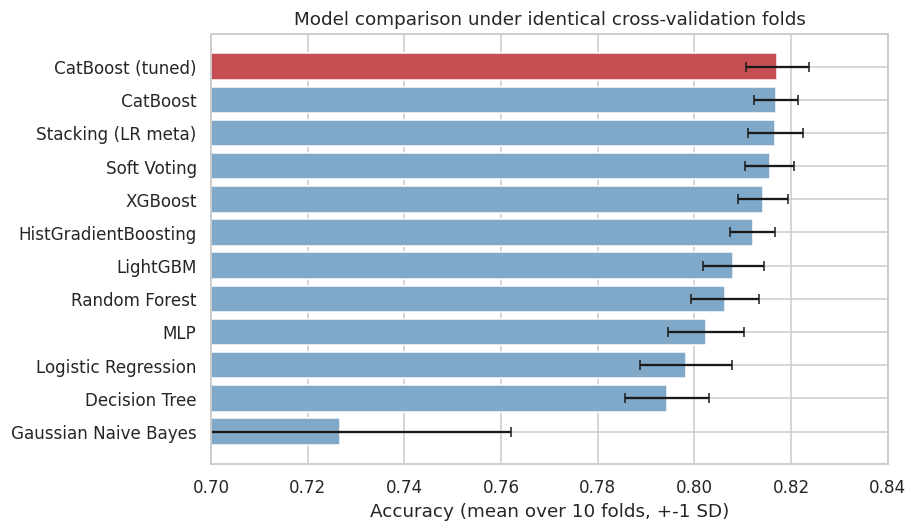

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5))
order = summary.index[::-1]
ax.barh(order, summary.loc[order, "accuracy"],
        xerr=summary.loc[order, "acc_sd"], capsize=3,
        color=["#c44e52" if n == summary.index[0] else "#7fa8c9" for n in order])
ax.set(xlim=(0.70, 0.84), xlabel="Accuracy (mean over 10 folds, +-1 SD)",
       title="Model comparison under identical cross-validation folds")
plt.tight_layout(); plt.show()

### 5.1 Paired Wilcoxon signed-rank test

Because all models saw identical folds, their scores are paired. The test below
asks whether the leading model's advantage over each competitor is larger than
fold-to-fold noise. `p >= 0.05` means the difference is **not** established —
which, as the results show, is the case for both the tuned model and both
ensembles.

In [10]:
best_name = summary.index[0]
rows = []
for name in summary.index[1:]:
    a = results[best_name].accuracy.values
    b = results[name].accuracy.values
    stat, p = wilcoxon(a, b)
    rows.append({"Model": name,
                 "Mean difference": a.mean() - b.mean(),
                 "p-value": p,
                 "Significant (a=0.05)": "yes" if p < 0.05 else "no"})

test_table = pd.DataFrame(rows)
print(f"Reference model: {best_name}\n")
test_table.round(4)

Reference model: CatBoost (tuned)



,Model,Mean difference,p-value,Significant (a=0.05)
0,CatBoost,0.0003,0.7695,no
1,Stacking (LR meta),0.0004,0.7930,no
2,Soft Voting,0.0016,0.3125,no
3,XGBoost,0.0030,0.2754,no
4,HistGradientBoosting,0.0051,0.0039,yes
5,LightGBM,0.0091,0.0039,yes
6,Random Forest,0.0108,0.0020,yes
7,MLP,0.0148,0.0020,yes
8,Logistic Regression,0.0189,0.0020,yes
9,Decision Tree,0.0228,0.0020,yes


## 6. Feature ablation

Which block of engineered features actually carries the signal? Each
configuration is scored with the same protocol and the same tuned model, so the
differences are attributable to the features alone.

In [11]:
spend_cols = [c for c in X.columns if c.startswith("log_")] + \
             ["NoSpend", "NumServices", "IsChild"]
region_cols = [c for c in X.columns if c.startswith("ShipRegion_")]
group_cols = ["GroupSize", "FamilySize", "Solo"]
base_cols = [c for c in X.columns
             if c not in spend_cols + region_cols + group_cols]

CONFIGS = {
    "A: demographics + cabin": base_cols,
    "B: A + group / family": base_cols + group_cols,
    "C: B + spending": base_cols + group_cols + spend_cols,
    "D: C + ship region (full)": list(X.columns),
}

ablation = {}
for name, cols in CONFIGS.items():
    d = evaluate(lambda s: CatBoostClassifier(**BEST_PARAMS, random_state=s,
                                              verbose=False,
                                              thread_count=N_JOBS),
                 X[cols], y)
    ablation[name] = d
    print(f"{name:28s} n={len(cols):3d}  "
          f"acc={d.accuracy.mean():.4f}+-{d.accuracy.std():.4f}  "
          f"auc={d.roc_auc.mean():.4f}")

A: demographics + cabin      n= 16  acc=0.7536+-0.0074  auc=0.8202


B: A + group / family        n= 19  acc=0.7538+-0.0081  auc=0.8189


C: B + spending              n= 30  acc=0.8174+-0.0067  auc=0.9083


D: C + ship region (full)    n= 35  acc=0.8172+-0.0065  auc=0.9082


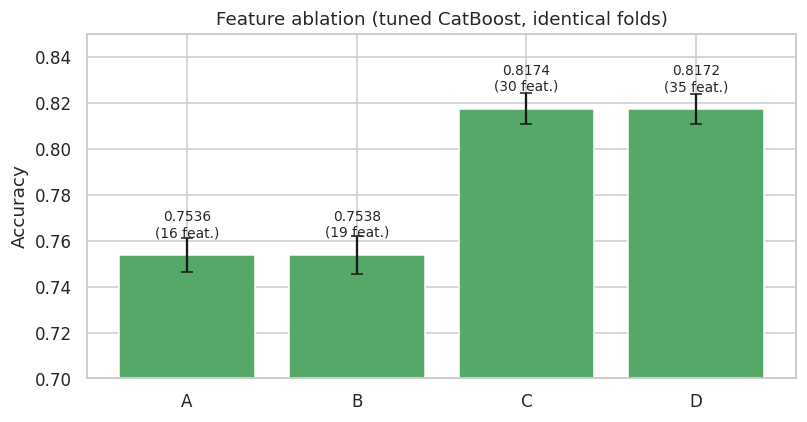

,n_features,accuracy,acc_sd,roc_auc
A: demographics + cabin,16,0.7536,0.0074,0.8202
B: A + group / family,19,0.7538,0.0081,0.8189
C: B + spending,30,0.8174,0.0067,0.9083
D: C + ship region (full),35,0.8172,0.0065,0.9082


In [12]:
abl_df = pd.DataFrame({
    "n_features": [len(CONFIGS[k]) for k in CONFIGS],
    "accuracy": [ablation[k].accuracy.mean() for k in CONFIGS],
    "acc_sd": [ablation[k].accuracy.std() for k in CONFIGS],
    "roc_auc": [ablation[k].roc_auc.mean() for k in CONFIGS],
}, index=list(CONFIGS))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(range(len(abl_df)), abl_df["accuracy"], yerr=abl_df["acc_sd"],
       capsize=4, color="#55a868")
ax.set_xticks(range(len(abl_df)))
ax.set_xticklabels([k.split(":")[0] for k in abl_df.index])
ax.set(ylim=(0.70, 0.85), ylabel="Accuracy",
       title="Feature ablation (tuned CatBoost, identical folds)")
for i, (v, n) in enumerate(zip(abl_df["accuracy"], abl_df["n_features"])):
    ax.text(i, v + 0.008, f"{v:.4f}\n({n} feat.)", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

abl_df.round(4)

In [13]:
a = ablation["C: B + spending"].accuracy.values
b = ablation["B: A + group / family"].accuracy.values
print(f"Adding the spending block: {a.mean() - b.mean():+.4f} accuracy, "
      f"p = {wilcoxon(a, b).pvalue:.4f}")

a = ablation["B: A + group / family"].accuracy.values
b = ablation["A: demographics + cabin"].accuracy.values
print(f"Adding group / family:     {a.mean() - b.mean():+.4f} accuracy, "
      f"p = {wilcoxon(a, b).pvalue:.4f}")

a = ablation["D: C + ship region (full)"].accuracy.values
b = ablation["C: B + spending"].accuracy.values
print(f"Adding ship region:        {a.mean() - b.mean():+.4f} accuracy, "
      f"p = {wilcoxon(a, b).pvalue:.4f}")

Adding the spending block: +0.0636 accuracy, p = 0.0020
Adding group / family:     +0.0002 accuracy, p = 0.8223
Adding ship region:        -0.0002 accuracy, p = 0.8457


## 7. Error analysis and interpretation

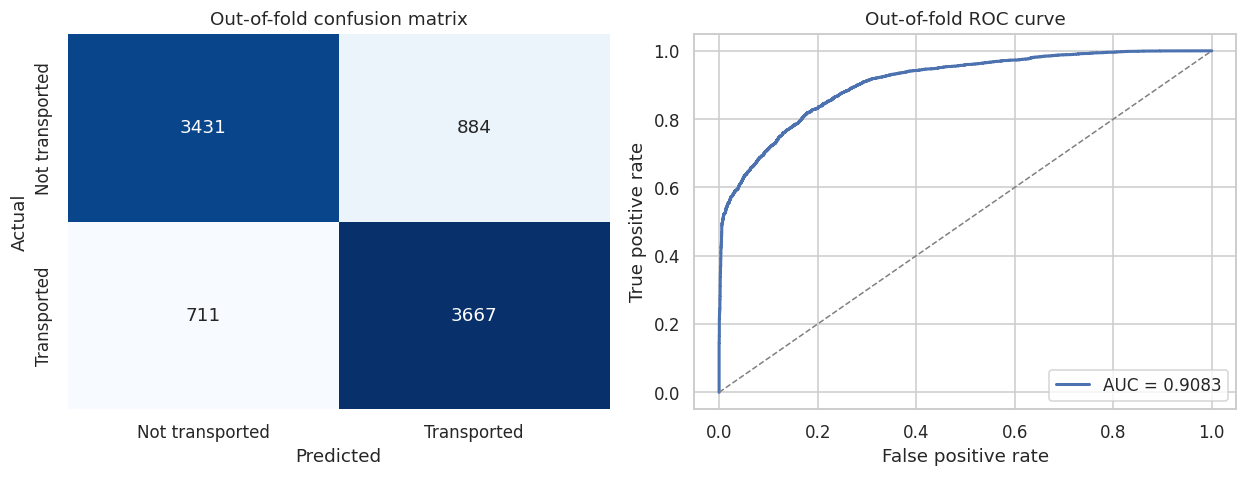

Out-of-fold accuracy: 0.8165


In [14]:
cv = StratifiedKFold(N_SPLITS, shuffle=True, random_state=0)
oof_proba = np.zeros(len(X))
for tr, va in cv.split(X, y):
    m = CatBoostClassifier(**BEST_PARAMS, random_state=0, verbose=False,
                           thread_count=N_JOBS)
    m.fit(X.iloc[tr], y.iloc[tr])
    oof_proba[va] = m.predict_proba(X.iloc[va])[:, 1]
oof_pred = (oof_proba > 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
cm = confusion_matrix(y, oof_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Not transported", "Transported"],
            yticklabels=["Not transported", "Transported"])
axes[0].set(xlabel="Predicted", ylabel="Actual",
            title="Out-of-fold confusion matrix")

fpr, tpr, _ = roc_curve(y, oof_proba)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y, oof_proba):.4f}")
axes[1].plot([0, 1], [0, 1], "--", c="grey", lw=1)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
            title="Out-of-fold ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"Out-of-fold accuracy: {accuracy_score(y, oof_pred):.4f}")

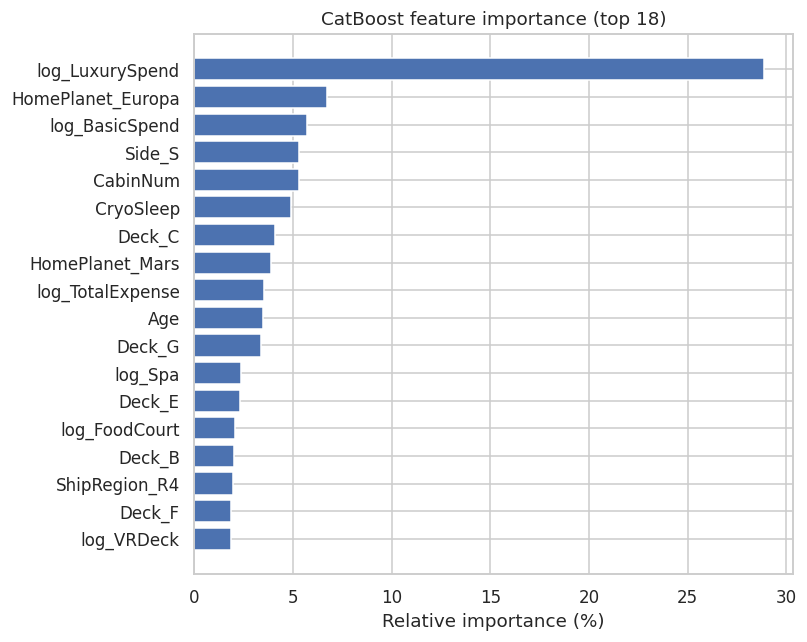

Spending block share of total importance: 50.2%
Group / family block share: 1.6%
Ship region block share:    3.1%


In [15]:
final_model = CatBoostClassifier(**BEST_PARAMS, random_state=0,
                                 verbose=False, thread_count=N_JOBS)
final_model.fit(X, y)

importance = pd.Series(final_model.get_feature_importance(),
                       index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 6))
top = importance.head(18)[::-1]
ax.barh(top.index, top.values, color="#4c72b0")
ax.set(xlabel="Relative importance (%)",
       title="CatBoost feature importance (top 18)")
plt.tight_layout(); plt.show()

print(f"Spending block share of total importance: "
      f"{importance[[c for c in spend_cols if c in importance.index]].sum():.1f}%")
print(f"Group / family block share: {importance[group_cols].sum():.1f}%")
print(f"Ship region block share:    {importance[region_cols].sum():.1f}%")

### Where the model fails

Comparing the passengers the model gets right against those it gets wrong shows
that errors concentrate in the region where the dominant rule breaks down:
passengers who did spend money but were transported anyway, and passengers in
cryosleep who were not.

In [16]:
err = X.copy()
err["correct"] = (oof_pred == y).astype(int)
err["confidence"] = np.abs(oof_proba - 0.5) * 2

profile = err.groupby("correct")[["log_TotalExpense", "CryoSleep", "Age",
                                  "GroupSize", "confidence"]].mean()
profile.index = ["Misclassified", "Correct"]
print(profile.round(3).to_string())

print(f"\nAccuracy among no-spend passengers   : "
      f"{err.loc[err.NoSpend == 1, 'correct'].mean():.4f} "
      f"(n={int((err.NoSpend == 1).sum())})")
print(f"Accuracy among spending passengers   : "
      f"{err.loc[err.NoSpend == 0, 'correct'].mean():.4f} "
      f"(n={int((err.NoSpend == 0).sum())})")

               log_TotalExpense  CryoSleep     Age  GroupSize  confidence
Misclassified             3.932      0.350  27.368      2.070       0.331
Correct                   4.330      0.361  29.101      2.028       0.686

Accuracy among no-spend passengers   : 0.8070 (n=3648)
Accuracy among spending passengers   : 0.8234 (n=5045)


## 8. Final model and submission

The submitted model averages predicted probabilities over three random seeds,
which removes the run-to-run variation of a single fit without changing the
architecture. Every model is refitted on the complete training set.

In [17]:
FINAL_SEEDS = [0, 1, 2]
test_proba = np.zeros(len(X_test))
for s in FINAL_SEEDS:
    m = CatBoostClassifier(**BEST_PARAMS, random_state=s, verbose=False,
                           thread_count=N_JOBS)
    m.fit(X, y)
    test_proba += m.predict_proba(X_test)[:, 1]
test_proba /= len(FINAL_SEEDS)

submission = pd.DataFrame({"PassengerId": test_ids,
                           "Transported": test_proba > 0.5})
submission.to_csv("submission.csv", index=False)

print(f"Rows: {len(submission)}")
print(submission["Transported"].value_counts().to_dict())
print(f"Predicted positive rate: {submission['Transported'].mean():.4f} "
      f"(training rate: {y.mean():.4f})")
submission.head()

Rows: 4277
{True: 2258, False: 2019}
Predicted positive rate: 0.5279 (training rate: 0.5036)


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


### Summary of findings

1. **Gradient boosting on engineered tabular features is the ceiling here.**
   CatBoost leads, with XGBoost and HistGradientBoosting statistically
   indistinguishable from it.
2. **Hyperparameter search bought nothing measurable.** The tuned configuration
   does not beat sensible defaults at the 5% level.
3. **Neither ensemble helped.** Stacking and soft voting land inside the noise
   band of the single best model, at several times the training cost.
4. **The engineered spending features are the entire story.** Removing them
   costs about six accuracy points; group, family and ship-region features
   contribute nothing detectable.

The practical reading is that on a dataset of this size and structure, effort
spent on representation dominates effort spent on model complexity.